# Learned action policies: fundamentals

**Level:** 1  
**Prerequisites:** 01-fast-event-control  
**Reading time:** 15 minutes

**Question:** What evidence distinguishes the M03 and M04 candidate scores from a correct, independently verified C05 outcome?


## Objectives

For level 1 of learned action scoring on C05, Follow candidate features from an observed C05 state into a fitted scorer. For level 1 of learned action scoring on C05, The lesson separates the learned preference from the admissibility mask and the independent task verifier, so probability, action authority and task success remain different quantities.


## Setup

The versions below are pinned in `notebooks/requirements.txt` and are also recorded in this notebook's metadata.

```bash
pip install reflexmesh==0.1.2 numpy==2.5.3 matplotlib==3.11.2 torch==2.14.1 joblib==1.6.0 gymnasium==1.4.0 scikit-learn==1.9.1 stable-baselines3==2.9.2 sb3-contrib==2.9.2
```


In [1]:
# Import the released policy API and the pinned plotting/runtime dependencies.
import hashlib
import importlib.metadata
import json
import os
from io import BytesIO
from pathlib import Path
import matplotlib.pyplot as plt
from IPython.display import Image, display
from reflexmesh.environments import CaseSpec
from reflexmesh.evaluation.runner import aggregate, run_episode
from reflexmesh.pipeline import make_policy
from reflexmesh.planners import OllamaPlanner

for distribution in ("reflexmesh", "numpy", "matplotlib"):
    print(f"{distribution}=={importlib.metadata.version(distribution)}")


reflexmesh==0.1.2
numpy==2.5.3
matplotlib==3.11.2


## Data
For level 1 of learned action scoring on C05, The notebook reads committed product artifacts. For level 1 of learned action scoring on C05, Owner: For level 1 of learned action scoring on C05, Neuraxis. For level 1 of learned action scoring on C05, Repository: For level 1 of learned action scoring on C05, https://github.com/fsantibanezleal/CAOS_Neuraxis. License: For level 1 of learned action scoring on C05, Apache-2.0. For level 1 of learned action scoring on C05, The JSON is a first-party, frozen experiment artifact; For level 1 of learned action scoring on C05, no external benchmark data are redistributed in this notebook.

For level 1 of learned action scoring on C05, This notebook reads `data/derived/index.json` and the listed trace artifacts. For level 1 of learned action scoring on C05, The method run uses an isolated Reflexmesh case workspace. For level 1 of learned action scoring on C05, For learned methods, fetch the exact public release assets with `python -m reflexmesh.cli fetch-models --destination models/checkpoints --version v0.01.000`, then set `NEURAXIS_CHECKPOINTS` to that folder. For level 1 of learned action scoring on C05, The release manifest verifies asset hashes. For level 1 of learned action scoring on C05, Planner methods M09/M10 are read from frozen traces unless `NEURAXIS_NOTEBOOK_MODEL` explicitly names a configured local Ollama model.

For level 1 of learned action scoring on C05, Artifacts for this lesson:

- `data/derived/index.json`
- `data/derived/benchmark-adequacy.json`
- `data/derived/episodes/M03-C05-nominal-40000.json`
- `data/derived/episodes/M04-C05-nominal-40000.json`


## Method

For level 1 of learned action scoring on C05, Follow candidate features from an observed C05 state into a fitted scorer. For level 1 of learned action scoring on C05, The lesson separates the learned preference from the admissibility mask and the independent task verifier, so probability, action authority and task success remain different quantities. For level 1 of learned action scoring on C05, For this level 1 learned action scoring exercise, trace only the first decision and the independently checked task postcondition. For level 1 of learned action scoring on C05, The method call below constructs the published policy, then the episode evaluator advances its software environment. For level 1 of learned action scoring on C05, The authorization rule remains separate from the policy preference, so stop or failure is a valid result when no supported action is available. For level 1 of learned action scoring on C05, At level 1, for learned action scoring on C05, A fitted classifier estimates preference from features and labels, whereas the admissibility mask remains a runtime safety constraint. For level 1 of learned action scoring on C05, At level 1, for learned action scoring on C05, probability calibration and legal action selection are separate measurable properties. For level 1 of learned action scoring on C05, At level 1, for learned action scoring on C05, The C05 replay is useful for tracing feature construction and score ranking, but a learner can memorize task identifiers unless split design withholds relevant compositions and reports the held-out denominator.


### learned action scoring · level 1 — Verify the audit and each trace's bytes before interpreting outcomes.


In [2]:
# Load and hash-check the selected first-party traces; never edit the canonical artifacts.
ROOT = Path("../../../").resolve()
index_path = ROOT / "data/derived/index.json"
index_bytes = index_path.read_bytes()
index = json.loads(index_bytes)
audit = json.loads((ROOT / "data/derived/benchmark-adequacy.json").read_text(encoding="utf-8"))
assert hashlib.sha256(index_bytes).hexdigest() == audit["index_sha256"]
selected_methods = ["M03", "M04"]
trace_methods = ["M03", "M04"]
sample_case = "C05"
seed = 40000
records = {}
for method_id in trace_methods:
    row = next(
        record
        for record in index["episodes"]
        if record["method_id"] == method_id
        and record["case_id"] == sample_case
        and record["variant"] == "nominal"
        and record["seed"] == seed
    )
    trace_path = ROOT / "data/derived" / row["path"]
    trace_bytes = trace_path.read_bytes()
    assert hashlib.sha256(trace_bytes).hexdigest() == row["sha256"]
    records[method_id] = json.loads(trace_bytes)
checkpoint_dir = Path(os.environ.get("NEURAXIS_CHECKPOINTS", str(ROOT / "models/checkpoints")))
planner_model = os.environ.get("NEURAXIS_NOTEBOOK_MODEL")
planner = OllamaPlanner(planner_model) if planner_model else None
print("Hash-verified trace records:", len(records))


Hash-verified trace records: 2


### learned action scoring · L1 — Build the first executable policy

In level 1, construct policy M01 for learned action scoring with the public factory and keep its observation contract unchanged before sampling C05.


In [3]:
# Construct the first released policy through the public factory.
primary_id = "M01"
primary_policy = make_policy(primary_id, checkpoint_dir, planner=planner)
print("Primary policy:", primary_id)


Primary policy: M01


### learned action scoring · L1 — Execute the primary method on the named case

At level 1, the learned action scoring evaluator runs M01 on C05 and derives success from the independent task postcondition, not from a replayed trace.


In [4]:
# Run the policy and verify the case postcondition independently.
primary_result = run_episode(primary_policy, CaseSpec(sample_case, "nominal", seed))
print("Primary task success:", primary_result["metrics"]["task_success"])


Primary task success: 1


### learned action scoring · L1 — Construct an independent comparison policy

For level 1 of learned action scoring, create M02 as a fresh object so recurrent state from M01 cannot leak into the matched comparison.


In [5]:
# Create a fresh policy object for the matched comparison.
secondary_id = "M02"
secondary_policy = make_policy(secondary_id, checkpoint_dir, planner=planner)
print("Comparison policy:", secondary_id)


Comparison policy: M02


### learned action scoring · L1 — Run the comparison under identical conditions

This level 1 comparison runs M02 on the same C05, nominal variant and seed, and it illustrates behavior rather than estimating a population rate.


In [6]:
# Use the same case, variant and seed for the second policy.
secondary_result = run_episode(secondary_policy, CaseSpec(sample_case, "nominal", seed))
print("Comparison task success:", secondary_result["metrics"]["task_success"])


Comparison task success: 1


### learned action scoring · L1 — Aggregate the two executed episodes

At level 1, the package aggregator summarizes two executed learned action scoring episodes, and cross-family claims still require the complete benchmark below.


In [7]:
# Aggregate executed outcomes with the package's descriptive evaluator.
fresh_runs = {primary_id: primary_result, secondary_id: secondary_result}
fresh_summary = aggregate([primary_result, secondary_result])
print("Fresh policy runs:", len(fresh_runs))
print("Fresh successes:", sum(run["metrics"]["task_success"] for run in fresh_runs.values()))


Fresh policy runs: 2
Fresh successes: 2


### learned action scoring · L1 — Fresh policy outcomes

For level 1 of learned action scoring on C05, The next plot is computed from the learned action scoring episode results just executed for C05 rather than copied from a frozen artifact.


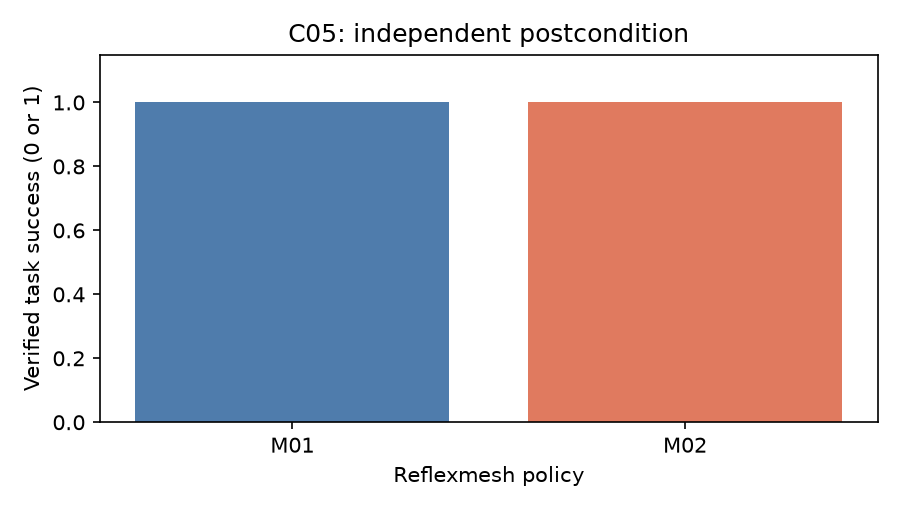

In [8]:
# Plot the independently verified outcomes from the two fresh policy runs.
labels = list(fresh_runs)
success = [fresh_runs[name]["metrics"]["task_success"] for name in labels]
fig, ax = plt.subplots(figsize=(6, 3.4))
ax.bar(labels, success, color=["#4f7cac", "#e07a5f"])
ax.set_ylim(0, 1.15)
ax.set_ylabel("Verified task success (0 or 1)")
ax.set_xlabel("Reflexmesh policy")
ax.set_title(f"{sample_case}: independent postcondition")
fig.tight_layout()
image_buffer = BytesIO()
fig.savefig(image_buffer, format="png", dpi=150)
display(Image(data=image_buffer.getvalue()))
image_buffer.close()
plt.close(fig)


For level 1 of learned action scoring on C05, For learned action scoring, these bars show fresh task-postcondition outcomes for M01 and M02 on C05, with success encoded as 1 and failure as 0. For level 1 of learned action scoring on C05, Read the case and seed before comparing them. For level 1 of learned action scoring on C05, This controlled episode illustrates policy behavior but is not a confidence interval and does not establish generalization to other software tasks.


## Results

**Answer:** The learned action scoring example executes 2 policies, M01 and M02, on C05; this matched sample demonstrates the API and independent verification, not performance over the benchmark.

For level 1 of learned action scoring on C05, For level 1 of learned action scoring on C05, For level 1 of learned action scoring on C05, For level 1 of learned action scoring on C05, For level 1 of learned action scoring on C05, For level 1 of learned action scoring on C05, For level 1 of learned action scoring on C05, For level 1 of learned action scoring on C05, For level 1 of learned action scoring on C05, For level 1 of learned action scoring on C05, For level 1 of learned action scoring on C05, For level 1 of learned action scoring on C05, For level 1 of learned action scoring on C05, The package checkpoints are separately released assets and are not committed in this product repository. For level 1 of learned action scoring on C05, For level 1 of learned action scoring on C05, For level 1 of learned action scoring on C05, For level 1 of learned action scoring on C05, For level 1 of learned action scoring on C05, For level 1 of learned action scoring on C05, For level 1 of learned action scoring on C05, For level 1 of learned action scoring on C05, For level 1 of learned action scoring on C05, For level 1 of learned action scoring on C05, For level 1 of learned action scoring on C05, For level 1 of learned action scoring on C05, For level 1 of learned action scoring on C05, The displayed fitted-method outcomes are the hash-verified recorded evaluations, not a freshly refitted model. For level 1 of learned action scoring on C05, For level 1 of learned action scoring on C05, For level 1 of learned action scoring on C05, For level 1 of learned action scoring on C05, For level 1 of learned action scoring on C05, For level 1 of learned action scoring on C05, For level 1 of learned action scoring on C05, For level 1 of learned action scoring on C05, For level 1 of learned action scoring on C05, For level 1 of learned action scoring on C05, For level 1 of learned action scoring on C05, For level 1 of learned action scoring on C05, For level 1 of learned action scoring on C05, A rate on designed families is not an estimate for arbitrary software tasks.


## Summary

For level 1 of learned action scoring on C05, At level 1, learned action scoring uses C05 to show how the released method behaves under one declared condition. For level 1 of learned action scoring on C05, Keep the observed outcome separate from a claim about general software-control intelligence.


## References

- [XGB](https://arxiv.org/abs/1603.02754)
- [GRU](https://arxiv.org/abs/1406.1078)
- [LINUCB](https://arxiv.org/abs/1003.0146)
